In [5]:
import pandas as pd
df = pd.read_csv("../data/raw/telco_churn.csv")
print(df.shape)
df.head()


(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
import os
print(os.listdir("../data/raw"))
print(os.path.getsize("../data/raw/telco_churn.csv"))

['telco_churn.csv']
977501


In [7]:
df.info()
print(df["Churn"].value_counts(normalize=True))
print(df.isnull().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [8]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].isnull().sum())
df[df["TotalCharges"].isnull()][["tenure", "MonthlyCharges", "TotalCharges"]]

11


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


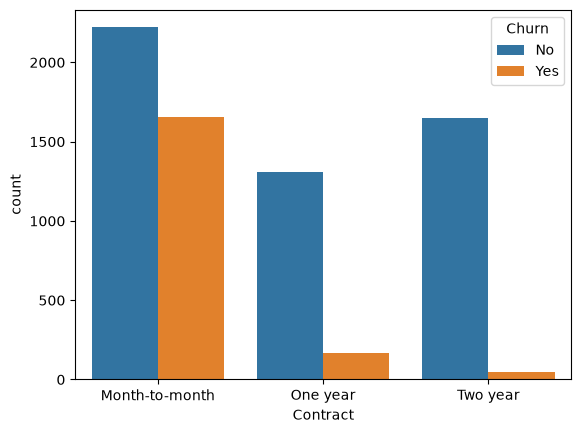

In [9]:
import seaborn as sns, matplotlib.pyplot as plt
sns.countplot(data=df, x="Contract", hue="Churn")
plt.show()

In [10]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["Churn"] = (df["Churn"] == "Yes").astype(int)
print(df["Churn"].mean())

0.2653698707936959


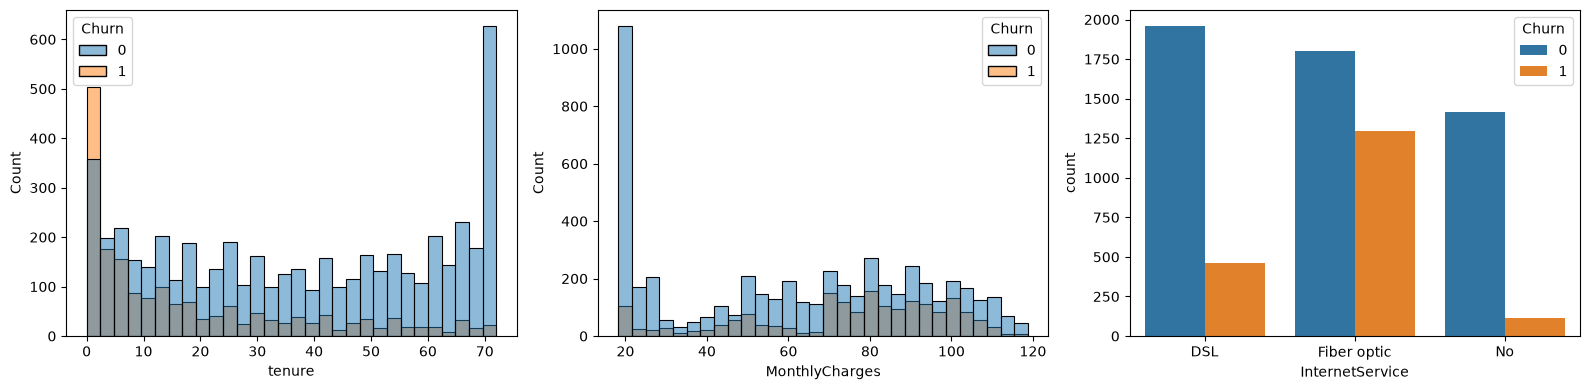

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, ax=ax[0])
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", bins=30, ax=ax[1])
sns.countplot(data=df, x="InternetService", hue="Churn", ax=ax[2])
plt.tight_layout()
plt.show()

In [12]:
print(df.groupby("PaymentMethod")["Churn"].mean().sort_values())
print(df.groupby("Contract")["Churn"].mean())

PaymentMethod
Credit card (automatic)      0.152431
Bank transfer (automatic)    0.167098
Mailed check                 0.191067
Electronic check             0.452854
Name: Churn, dtype: float64
Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn, dtype: float64


## Key EDA Insights
- Overall churn: ~26.5% (imbalanced, so use AUC / recall / PR-AUC)
- Month-to-month contracts: 42.7% churn vs 2.8% for two-year
- Electronic check users: 45.3% churn vs ~15-19% for other methods
- Churners concentrate in the first ~10 months of tenure
- Fiber optic customers churn much more than DSL
- 11 rows had blank TotalCharges (all tenure = 0), filled with 0

In [13]:
from sklearn.model_selection import train_test_split

df = df.drop(columns=["customerID"])
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape, y_train.mean(), y_test.mean())

(5634, 19) (1409, 19) 0.2653532126375577 0.2654364797728886


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

baseline = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

baseline.fit(X_train, y_train)
proba = baseline.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print("ROC-AUC:", round(roc_auc_score(y_test, proba), 4))
print("PR-AUC:", round(average_precision_score(y_test, proba), 4))
print(classification_report(y_test, pred))

ROC-AUC: 0.8415
PR-AUC: 0.6325
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [16]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

models = {
    "xgboost": XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=neg / pos, eval_metric="logloss", random_state=42,
    ),
    "lightgbm": LGBMClassifier(
        n_estimators=300, learning_rate=0.05, num_leaves=15,
        class_weight="balanced", random_state=42, verbose=-1,
    ),
}

results = {"logreg": (roc_auc_score(y_test, proba), average_precision_score(y_test, proba))}

for name, m in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", m)])
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    results[name] = (roc_auc_score(y_test, p), average_precision_score(y_test, p))

for k, (roc, pr) in results.items():
    print(f"{k:10s} ROC-AUC={roc:.4f}  PR-AUC={pr:.4f}")

logreg     ROC-AUC=0.8415  PR-AUC=0.6325
xgboost    ROC-AUC=0.8399  PR-AUC=0.6570
lightgbm   ROC-AUC=0.8378  PR-AUC=0.6527


In [17]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, m in [("logreg", baseline.named_steps["model"])] + list(models.items()):
    pipe = Pipeline([("prep", preprocess), ("model", m)])
    s = cross_validate(pipe, X, y, cv=cv, scoring=["roc_auc", "average_precision"])
    print(f"{name:10s} ROC-AUC={s['test_roc_auc'].mean():.4f}±{s['test_roc_auc'].std():.4f}  "
          f"PR-AUC={s['test_average_precision'].mean():.4f}±{s['test_average_precision'].std():.4f}")

logreg     ROC-AUC=0.8449±0.0134  PR-AUC=0.6554±0.0271
xgboost    ROC-AUC=0.8434±0.0109  PR-AUC=0.6596±0.0216
lightgbm   ROC-AUC=0.8390±0.0103  PR-AUC=0.6510±0.0243


In [18]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_models = {
    "logreg": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "xgboost": models["xgboost"],
    "lightgbm": models["lightgbm"],
}

for name, m in cv_models.items():
    pipe = Pipeline([("prep", preprocess), ("model", m)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="average_precision")
    print(f"{name:10s} PR-AUC mean={scores.mean():.4f}  std={scores.std():.4f}")

logreg     PR-AUC mean=0.6601  std=0.0196
xgboost    PR-AUC mean=0.6660  std=0.0211
lightgbm   PR-AUC mean=0.6562  std=0.0234


## Model comparison (5-fold CV on train)
- LogReg: ROC-AUC 0.845, PR-AUC 0.660
- XGBoost: ROC-AUC 0.843, PR-AUC 0.666
- LightGBM: ROC-AUC 0.839, PR-AUC 0.656
- Differences are within CV noise, so final model = Logistic Regression (simplest, interpretable)

In [19]:
import numpy as np

cost_missed = 500    # lost customer revenue (₹), assumption
cost_offer = 100     # retention offer cost (₹), assumption

baseline.fit(X_train, y_train)
proba = baseline.predict_proba(X_test)[:, 1]

rows = []
for t in np.arange(0.1, 0.91, 0.05):
    pred = (proba >= t).astype(int)
    fn = ((pred == 0) & (y_test == 1)).sum()
    fp = ((pred == 1) & (y_test == 0)).sum()
    tp = ((pred == 1) & (y_test == 1)).sum()
    rows.append((round(t, 2), tp, fp, fn, fn * cost_missed + (tp + fp) * cost_offer))

res = pd.DataFrame(rows, columns=["threshold", "TP", "FP", "FN", "total_cost"])
print(res.sort_values("total_cost").head(5))

   threshold   TP   FP  FN  total_cost
5       0.35  338  418  36       93600
4       0.30  347  461  27       94300
6       0.40  324  370  50       94400
7       0.45  314  336  60       95000
3       0.25  351  512  23       97800


## Threshold tuning
- Assumed costs: missed churner = ₹500, retention offer = ₹100
- Best threshold 0.35 (total cost ₹93,600 on test set); flat between 0.30 and 0.40
- Chosen threshold is a business decision and shifts with cost assumptions

Background dataset has 5634 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5634 when initializing the masker.


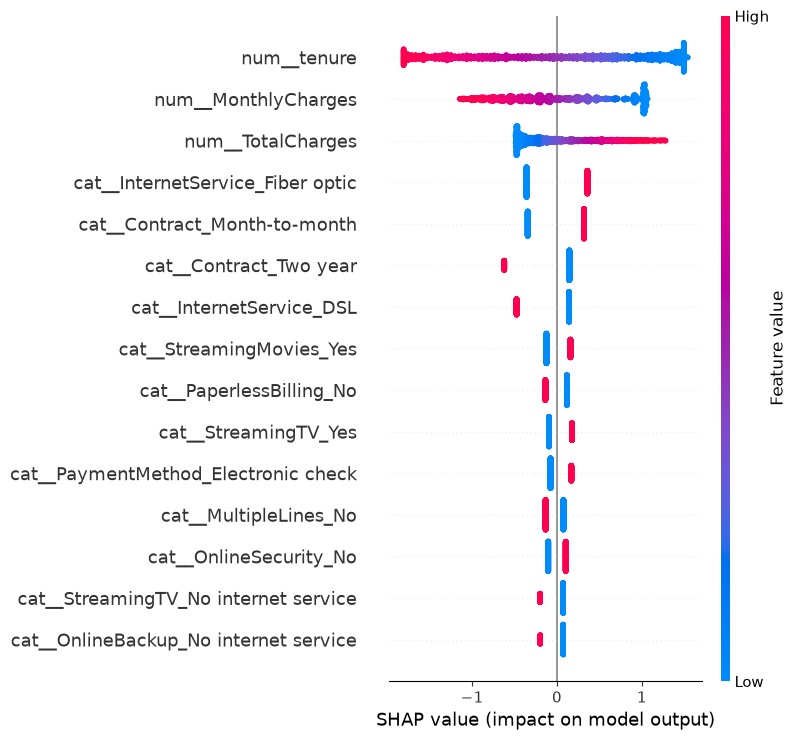

In [20]:
import shap

prep = baseline.named_steps["prep"]
clf = baseline.named_steps["model"]

X_train_t = prep.transform(X_train)
X_test_t = prep.transform(X_test)
feature_names = prep.get_feature_names_out()

explainer = shap.LinearExplainer(clf, X_train_t)
shap_values = explainer.shap_values(X_test_t)

shap.summary_plot(shap_values, X_test_t, feature_names=feature_names, max_display=15)

In [22]:
import pandas as pd, numpy as np

imp = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

print(imp.head(12))

                                feature  mean_abs_shap
0                           num__tenure       1.020652
1                   num__MonthlyCharges       0.579261
2                     num__TotalCharges       0.389658
17     cat__InternetService_Fiber optic       0.357878
37         cat__Contract_Month-to-month       0.330209
39               cat__Contract_Two year       0.258943
16             cat__InternetService_DSL       0.256632
36             cat__StreamingMovies_Yes       0.137065
40             cat__PaperlessBilling_No       0.125007
33                 cat__StreamingTV_Yes       0.124009
44  cat__PaymentMethod_Electronic check       0.106989
13                cat__MultipleLines_No       0.104593


In [23]:
coef = pd.Series(clf.coef_[0], index=feature_names).sort_values()
print(coef.head(8))
print(coef.tail(8))

num__tenure                                 -1.141091
cat__Contract_Two year                      -0.766446
num__MonthlyCharges                         -0.677256
cat__InternetService_DSL                    -0.617657
cat__OnlineSecurity_No internet service     -0.270347
cat__OnlineBackup_No internet service       -0.270347
cat__InternetService_No                     -0.270347
cat__DeviceProtection_No internet service   -0.270347
dtype: float64
cat__TechSupport_No                    0.171101
cat__OnlineSecurity_No                 0.205351
cat__PaymentMethod_Electronic check    0.244360
cat__StreamingTV_Yes                   0.270039
cat__StreamingMovies_Yes               0.282577
num__TotalCharges                      0.474357
cat__Contract_Month-to-month           0.662997
cat__InternetService_Fiber optic       0.715756
dtype: float64


In [24]:
import joblib, os
os.makedirs("../models", exist_ok=True)
joblib.dump(baseline, "../models/churn_pipeline.pkl")
joblib.dump(0.35, "../models/threshold.pkl")
print("saved")

saved


## Explainability
- LogReg coefficients and SHAP agree with EDA: short tenure, month-to-month contract and fiber optic raise churn risk; long tenure and two-year contract lower it
- Numeric features are correlated (TotalCharges ~ tenure x MonthlyCharges), so single coefficients are unstable